# **DEMO: DỰ ĐOÁN TỪ FILE SOLIDITY**

Quy trình đầy đủ từ mã nguồn tới dự đoán:

```
File .sol  ->  solc 0.5.17  ->  Runtime Bytecode  ->  Opcode
           ->  Vector 256 chiều  ->  K-Means + Autoencoder  ->  Nhãn
```

Dữ liệu demo gồm hai thư mục:

| Thư mục | Nội dung |
|---|---|
| `clean` | 6 hợp đồng không có lỗ hổng, áp dụng checks-effects-interactions và kiểm tra tràn số |
| `vulnerable` | 6 hợp đồng có lỗi: 2 Reentrancy, 2 Arithmetic, 2 goi toi dia chi khong xac dinh |

Tất cả dùng **cùng một compiler `solc 0.5.17`** để loại bỏ ảnh hưởng của phiên bản
trình biên dịch lên tần suất Opcode.

# **1. CÀI ĐẶT COMPILER**

In [1]:
!pip install -q py-solc-x

from pathlib import Path
import subprocess
import json
import collections
import os
import stat

SOLC_VERSION = "0.5.17"
SOLC_PATH = Path("/content/solc") / f"solc-{SOLC_VERSION}"
SOLC_PATH.parent.mkdir(parents=True, exist_ok=True)

if not SOLC_PATH.exists():
    url = (
        "https://github.com/ethereum/solidity/releases/download/"
        f"v{SOLC_VERSION}/solc-static-linux"
    )
    print("Đang tải solc", SOLC_VERSION, "...")
    subprocess.run(["wget", "-q", "-O", str(SOLC_PATH), url], check=True)
    SOLC_PATH.chmod(SOLC_PATH.stat().st_mode | stat.S_IEXEC)

version_output = subprocess.run(
    [str(SOLC_PATH), "--version"], capture_output=True, text=True
).stdout.strip()

print("========== COMPILER ==========")
print(version_output)

assert SOLC_VERSION in version_output, "Phiên bản solc không đúng"

Đang tải solc 0.5.17 ...
========== COMPILER ==========
solc, the solidity compiler commandline interface
Version: 0.5.17+commit.d19bba13.Linux.g++


# **2. KẾT NỐI DRIVE VÀ CẤU HÌNH**

In [2]:
from google.colab import drive
import pandas as pd
import numpy as np
import joblib
import time

drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/IS6002/EXPERIMENT/implementation")

# Thư mục chứa file Solidity
CONTRACTS_DIR = BASE_DIR / "data/demo_contracts"
DIR_CLEAN = CONTRACTS_DIR / "clean"
DIR_VULNERABLE = CONTRACTS_DIR / "vulnerable"

# Model K-Means
KMEANS_PATH = BASE_DIR / "algorithm_training/KMeans/minibatch_kmeans.joblib"

# Model Autoencoder
AE_DIR = BASE_DIR / "algorithm_training/Autoencoder"
AE_MODEL_PATH = AE_DIR / "autoencoder.keras"
AE_PACKAGE_PATH = AE_DIR / "autoencoder_package.joblib"

# Dataset gốc
RAW_CSV = BASE_DIR / "data/raw/opcode_by_contract.csv"

print("========== KIỂM TRA ĐƯỜNG DẪN ==========")

for name, path in [
    ("Thư mục clean", DIR_CLEAN),
    ("Thư mục vulnerable", DIR_VULNERABLE),
    ("Model K-Means", KMEANS_PATH),
    ("Model Autoencoder", AE_MODEL_PATH),
    ("Package Autoencoder", AE_PACKAGE_PATH)
]:
    print(f"  {name:22s}: {'có' if path.exists() else 'KHÔNG THẤY'}")

assert DIR_CLEAN.exists() and DIR_VULNERABLE.exists(), (
    "Chưa thấy thư mục contract tại "
    f"{CONTRACTS_DIR}"
)

sol_files = (
    sorted(DIR_CLEAN.glob("*.sol")) +
    sorted(DIR_VULNERABLE.glob("*.sol"))
)

print("\n========== FILE SOLIDITY ==========")
print("clean      :", len(list(DIR_CLEAN.glob("*.sol"))), "file")
print("vulnerable :", len(list(DIR_VULNERABLE.glob("*.sol"))), "file")
print("Tổng       :", len(sol_files), "file")

========== KIỂM TRA ĐƯỜNG DẪN ==========
  Thư mục clean         : có
  Thư mục vulnerable    : có
  Model K-Means         : có
  Model Autoencoder     : có
  Package Autoencoder   : có

========== FILE SOLIDITY ==========
clean      : 6 file
vulnerable : 6 file
Tổng       : 12 file


# **3. BỘ DISASSEMBLER EVM**

Chuyển bytecode thành chuỗi Opcode theo đúng quy tắc EVM.

Hai điểm quan trọng:

- **Toán hạng của `PUSH1`–`PUSH32` không được đếm như Opcode.** `PUSH1 0x60` là một Opcode,
  không phải hai.
- Byte không thuộc bảng Opcode được đặt tên `OP_XX` theo giá trị hex, giống cách
  đặt tên trong bộ dữ liệu huấn luyện.

In [5]:
OPCODES = {
    0x00: "STOP", 0x01: "ADD", 0x02: "MUL", 0x03: "SUB", 0x04: "DIV",
    0x05: "SDIV", 0x06: "MOD", 0x07: "SMOD", 0x08: "ADDMOD", 0x09: "MULMOD",
    0x0a: "EXP", 0x0b: "SIGNEXTEND",
    0x10: "LT", 0x11: "GT", 0x12: "SLT", 0x13: "SGT", 0x14: "EQ",
    0x15: "ISZERO", 0x16: "AND", 0x17: "OR", 0x18: "XOR", 0x19: "NOT",
    0x1a: "BYTE", 0x1b: "SHL", 0x1c: "SHR", 0x1d: "SAR",
    0x20: "SHA3",
    0x30: "ADDRESS", 0x31: "BALANCE", 0x32: "ORIGIN", 0x33: "CALLER",
    0x34: "CALLVALUE", 0x35: "CALLDATALOAD", 0x36: "CALLDATASIZE",
    0x37: "CALLDATACOPY", 0x38: "CODESIZE", 0x39: "CODECOPY",
    0x3a: "GASPRICE", 0x3b: "EXTCODESIZE", 0x3c: "EXTCODECOPY",
    0x3d: "RETURNDATASIZE", 0x3e: "RETURNDATACOPY", 0x3f: "EXTCODEHASH",
    0x40: "BLOCKHASH", 0x41: "COINBASE", 0x42: "TIMESTAMP", 0x43: "NUMBER",
    0x44: "DIFFICULTY", 0x45: "GASLIMIT", 0x46: "CHAINID",
    0x47: "SELFBALANCE",
    0x50: "POP", 0x51: "MLOAD", 0x52: "MSTORE", 0x53: "MSTORE8",
    0x54: "SLOAD", 0x55: "SSTORE", 0x56: "JUMP", 0x57: "JUMPI",
    0x58: "GETPC", 0x59: "MSIZE", 0x5a: "GAS", 0x5b: "JUMPDEST",
    0xf0: "CREATE", 0xf1: "CALL", 0xf2: "CALLCODE", 0xf3: "RETURN",
    0xf4: "DELEGATECALL", 0xf5: "CREATE2",
    0xfa: "STATICCALL", 0xfd: "REVERT", 0xfe: "INVALID",
    0xff: "SELFDESTRUCT",
}

for _i in range(1, 33):
    OPCODES[0x5f + _i] = "PUSH%d" % _i
for _i in range(1, 17):
    OPCODES[0x7f + _i] = "DUP%d" % _i
    OPCODES[0x8f + _i] = "SWAP%d" % _i
for _i in range(0, 5):
    OPCODES[0xa0 + _i] = "LOG%d" % _i


def disassemble(bytecode_hex):
    """Chuyen bytecode hex thanh danh sach ten opcode theo dung thu tu.

    Toan hang cua PUSH1..PUSH32 KHONG duoc dem nhu opcode.
    Byte khong hop le duoc dat ten OP_XX theo gia tri hex.
    """
    code = bytecode_hex.lower()
    if code.startswith("0x"):
        code = code[2:]
    if len(code) % 2 == 1:
        code = code[:-1]

    raw = bytes.fromhex(code)

    ops = []
    i = 0
    n = len(raw)

    while i < n:
        b = raw[i]
        name = OPCODES.get(b)

        if name is None:
            ops.append("OP_%02X" % b)
            i += 1
            continue

        ops.append(name)

        # PUSH1..PUSH32: bo qua toan hang
        if 0x60 <= b <= 0x7f:
            i += 1 + (b - 0x5f)
        else:
            i += 1

    return ops


# ========== UNIT TEST ==========
assert disassemble("6001600201") == ["PUSH1", "PUSH1", "ADD"]
assert disassemble("7f" + "11" * 32 + "00") == ["PUSH32", "STOP"]
assert disassemble("c1") == ["OP_C1"]
assert disassemble("60") == ["PUSH1"]
# Ten phai khop dung tu dien cua mo hinh: 0x58 la GETPC, 0x5F la OP_5F
assert disassemble("58") == ["GETPC"]
assert disassemble("5f") == ["OP_5F"]

print("========== DISASSEMBLER ==========")
print("Số Opcode trong bảng:", len(OPCODES))
print("Unit test: PUSH1 0x01 PUSH1 0x02 ADD ->", disassemble("6001600201"))
print("Toán hạng của PUSH không bị đếm thành Opcode.")
print("Tên Opcode khớp từ điển 256 đặc trưng của mô hình.")

========== DISASSEMBLER ==========
Số Opcode trong bảng: 142
Unit test: PUSH1 0x01 PUSH1 0x02 ADD -> ['PUSH1', 'PUSH1', 'ADD']
Toán hạng của PUSH không bị đếm thành Opcode.
Tên Opcode khớp từ điển 256 đặc trưng của mô hình.


# **4. BIÊN DỊCH VÀ TRÍCH XUẤT OPCODE**

In [6]:
def compile_runtime_bytecode(sol_path):
    """Bien dich file .sol, tra ve runtime bytecode cua contract lon nhat trong file."""
    result = subprocess.run(
        [str(SOLC_PATH), "--combined-json", "bin-runtime", str(sol_path)],
        capture_output=True, text=True
    )

    if result.returncode != 0:
        raise RuntimeError(f"Biên dịch lỗi {sol_path.name}:\n{result.stderr[:500]}")

    payload = json.loads(result.stdout)
    candidates = [v["bin-runtime"] for v in payload["contracts"].values() if v["bin-runtime"]]

    if not candidates:
        raise RuntimeError(f"Không có runtime bytecode: {sol_path.name}")

    return max(candidates, key=len)


records = []

print("========== BIÊN DỊCH ==========")
print(f"{'File':34s} {'Nhãn':16s} {'Bytes':>8s} {'Opcode':>8s} {'Khác 0':>7s}")
print("-" * 78)

for sol_path in sol_files:
    label = "Non-vulnerable" if sol_path.parent.name == "clean" else "Vulnerable"

    bytecode = compile_runtime_bytecode(sol_path)
    opcodes = disassemble(bytecode)
    counts = collections.Counter(opcodes)

    records.append({
        "contract_id": sol_path.stem,
        "folder": sol_path.parent.name,
        "label": label,
        "counts": counts,
        "n_bytes": len(bytecode) // 2,
        "n_opcodes": len(opcodes)
    })

    print(f"{sol_path.name:34s} {label:16s} {len(bytecode) // 2:8,d} "
          f"{len(opcodes):8,d} {len(counts):7d}")

print("-" * 78)
print("Biên dịch thành công", len(records), "hợp đồng.")

========== BIÊN DỊCH ==========
File                               Nhãn                Bytes   Opcode  Khác 0
------------------------------------------------------------------------------
SafeAuction.sol                    Non-vulnerable     12,630    6,025      63
SafeEscrow.sol                     Non-vulnerable     13,210    6,372      72
SafeMultisig.sol                   Non-vulnerable     13,115    6,473      67
SafeRegistry.sol                   Non-vulnerable     12,583    5,982      68
SafeStaking.sol                    Non-vulnerable     12,857    6,381      64
SafeVault.sol                      Non-vulnerable     14,375    6,717      62
DelegateUnknown.sol                Vulnerable         11,764    6,013      68
OverflowToken.sol                  Vulnerable         11,418    5,423      67
ReentrancyBank.sol                 Vulnerable         11,703    5,639      62
ReentrancyVault.sol                Vulnerable         10,819    5,494      74
UnderflowWallet.sol            

# **5. NẠP MÔ HÌNH VÀ DỰNG VECTOR ĐẶC TRƯNG**

Vector đặc trưng phải có **đúng 256 cột, đúng thứ tự** mà mô hình đã học. Opcode nào
không xuất hiện thì để 0; Opcode nào không nằm trong danh sách của mô hình thì bỏ qua.

In [7]:
import tensorflow as tf
from tensorflow import keras

km_pkg = joblib.load(KMEANS_PATH)
kmeans_model = km_pkg["model"]
KM_VULNERABLE_CLUSTERS = set(km_pkg["vulnerable_clusters"])
KM_OFFSET = km_pkg.get("cluster_id_offset", 1)

autoencoder = keras.models.load_model(AE_MODEL_PATH)
ae_pkg = joblib.load(AE_PACKAGE_PATH)
AE_SCALER = ae_pkg["scaler"]
AE_THRESHOLD = float(ae_pkg["threshold"])

OPCODE_FEATURES = list(km_pkg["opcode_features"])
assert OPCODE_FEATURES == list(ae_pkg["opcode_features"]), \
    "Hai mô hình dùng danh sách Opcode khác nhau"

print("========== MÔ HÌNH ==========")
print("K-Means      : ", kmeans_model.n_clusters, "cụm | cụm Vulnerable:",
      sorted(KM_VULNERABLE_CLUSTERS))
print("Autoencoder  : ngưỡng", f"{AE_THRESHOLD:.10f}")
print("Số đặc trưng : ", len(OPCODE_FEATURES))

# ===== Dung ma tran dac trung =====
feature_index = {name: i for i, name in enumerate(OPCODE_FEATURES)}

X = np.zeros((len(records), len(OPCODE_FEATURES)), dtype=np.float64)
unmatched = collections.Counter()

for row, rec in enumerate(records):
    for op_name, value in rec["counts"].items():
        col = feature_index.get(op_name)
        if col is None:
            unmatched[op_name] += value
        else:
            X[row, col] = value

X_demo = pd.DataFrame(X, columns=OPCODE_FEATURES)

info = pd.DataFrame([{k: r[k] for k in ("contract_id", "folder", "label", "n_opcodes")}
                     for r in records])

y_true = (info["label"] == "Vulnerable").astype(int).to_numpy()

print("\n========== MA TRẬN ĐẶC TRƯNG ==========")
print("Kích thước:", X_demo.shape)
print("Tổng Opcode mỗi hợp đồng: từ", f"{int(X_demo.sum(axis=1).min()):,}",
      "đến", f"{int(X_demo.sum(axis=1).max()):,}")

if unmatched:
    total_unmatched = sum(unmatched.values())
    total_all = sum(sum(r["counts"].values()) for r in records)
    print(f"\nOpcode không có trong danh sách của mô hình: {len(unmatched)} loại, "
          f"{total_unmatched:,} lượt ({total_unmatched / total_all * 100:.3f}%)")
    print("Thường gặp nhất:", unmatched.most_common(5))
else:
    print("\nMọi Opcode đều khớp danh sách đặc trưng của mô hình.")

assert (X_demo.sum(axis=1) > 0).all(), "Có hợp đồng không chứa Opcode"

========== MÔ HÌNH ==========
K-Means      :  6 cụm | cụm Vulnerable: [1, 3, 4]
Autoencoder  : ngưỡng 0.0000629042
Số đặc trưng :  256

========== MA TRẬN ĐẶC TRƯNG ==========
Kích thước: (12, 256)
Tổng Opcode mỗi hợp đồng: từ 5,423 đến 6,717

Mọi Opcode đều khớp danh sách đặc trưng của mô hình.


# **6. DỰ ĐOÁN**

In [8]:
# ===== K-Means: log1p roi chia theo hang =====
X_log = np.log1p(X_demo)
X_km = X_log.div(X_log.sum(axis=1), axis=0)

km_clusters = kmeans_model.predict(X_km.to_numpy(dtype="float64")) + KM_OFFSET
km_pred = np.array([1 if c in KM_VULNERABLE_CLUSTERS else 0 for c in km_clusters])

# ===== Autoencoder: log1p roi MinMaxScaler da luu, clip ve [0,1] =====
X_ae = np.clip(
    AE_SCALER.transform(np.log1p(X_demo.to_numpy(dtype="float64"))),
    0.0, 1.0
).astype(np.float32)

reconstructed = autoencoder.predict(X_ae, batch_size=256, verbose=0)
ae_errors = np.mean(np.square(X_ae - reconstructed), axis=1)
ae_pred = (ae_errors > AE_THRESHOLD).astype(int)


def to_label(v):
    return "Vulnerable" if v == 1 else "Non-vulnerable"


result = pd.DataFrame({
    "contract": info["contract_id"],
    "nhan_that": info["label"],
    "tong_opcode": X_demo.sum(axis=1).astype(int),
    "kmeans_cum": km_clusters,
    "kmeans": [to_label(v) for v in km_pred],
    "ae_error": ae_errors,
    "autoencoder": [to_label(v) for v in ae_pred]
})

result["kmeans_dung"] = km_pred == y_true
result["ae_dung"] = ae_pred == y_true

print("========== KẾT QUẢ DỰ ĐOÁN ==========")
print(result.to_string(index=False))

print("\n========== TỶ LỆ ĐÚNG ==========")
print(f"K-Means     : {int(result['kmeans_dung'].sum())}/{len(result)} "
      f"({result['kmeans_dung'].mean() * 100:.1f}%)")
print(f"Autoencoder : {int(result['ae_dung'].sum())}/{len(result)} "
      f"({result['ae_dung'].mean() * 100:.1f}%)")

========== KẾT QUẢ DỰ ĐOÁN ==========
          contract      nhan_that  tong_opcode  kmeans_cum         kmeans  ae_error autoencoder  kmeans_dung  ae_dung
       SafeAuction Non-vulnerable         6025           6 Non-vulnerable  0.003950  Vulnerable         True    False
        SafeEscrow Non-vulnerable         6372           6 Non-vulnerable  0.007787  Vulnerable         True    False
      SafeMultisig Non-vulnerable         6473           6 Non-vulnerable  0.003037  Vulnerable         True    False
      SafeRegistry Non-vulnerable         5982           6 Non-vulnerable  0.007322  Vulnerable         True    False
       SafeStaking Non-vulnerable         6381           6 Non-vulnerable  0.003303  Vulnerable         True    False
         SafeVault Non-vulnerable         6717           6 Non-vulnerable  0.001050  Vulnerable         True    False
   DelegateUnknown     Vulnerable         6013           4     Vulnerable  0.003852  Vulnerable         True     True
     OverflowToken

# **7. MA TRẬN NHẦM LẪN**

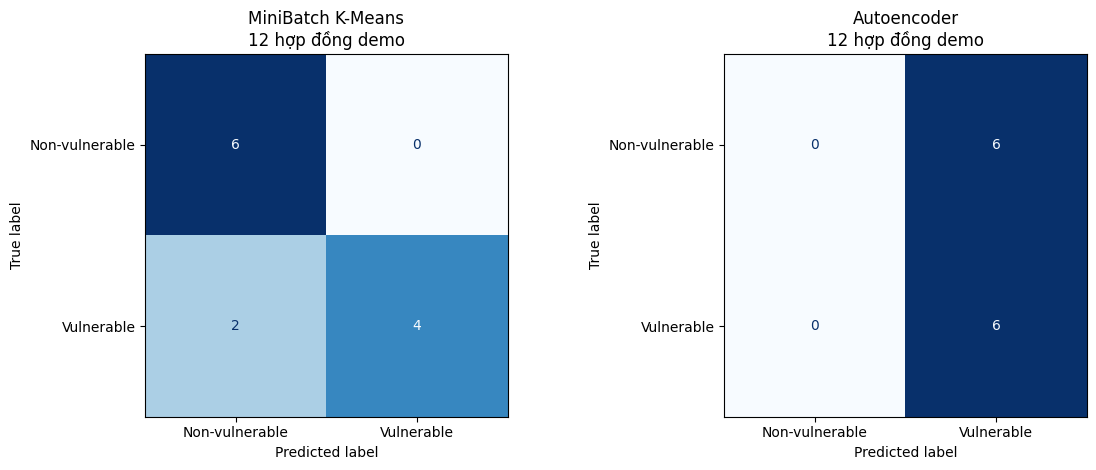


========== K-MEANS ==========
  Hợp đồng an toàn nhận đúng   : 6/6
  Hợp đồng an toàn báo nhầm    : 0/6
  Hợp đồng có lỗi phát hiện ra : 4/6
  Hợp đồng có lỗi bỏ sót       : 2/6

========== AUTOENCODER ==========
  Hợp đồng an toàn nhận đúng   : 0/6
  Hợp đồng an toàn báo nhầm    : 6/6
  Hợp đồng có lỗi phát hiện ra : 6/6
  Hợp đồng có lỗi bỏ sót       : 0/6


In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for ax, (name, pred) in zip(axes, [("MiniBatch K-Means", km_pred),
                                   ("Autoencoder", ae_pred)]):
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-vulnerable", "Vulnerable"]
    ).plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
    ax.set_title(f"{name}\n12 hợp đồng demo")

plt.tight_layout()
plt.show()

for name, pred in [("K-MEANS", km_pred), ("AUTOENCODER", ae_pred)]:
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    print(f"\n========== {name} ==========")
    print(f"  Hợp đồng an toàn nhận đúng   : {cm[0, 0]}/6")
    print(f"  Hợp đồng an toàn báo nhầm    : {cm[0, 1]}/6")
    print(f"  Hợp đồng có lỗi phát hiện ra : {cm[1, 1]}/6")
    print(f"  Hợp đồng có lỗi bỏ sót       : {cm[1, 0]}/6")